# hBN bilayer: results

Reference results of the first benchmark of the project (`docs/04_benchmark_systems.md`): bilayer hBN computed
explicitly (AA' and AB stackings) vs the monolayer, which will later be combined with the second layer treated as
an effective substrate (Notes, Sec. 2). This notebook collects the physical results only; the calculations, the
convergence studies and the checks are in `DFT_Analysis.ipynb` and `GW_Analysis.ipynb`.

Rule: this notebook reads **only** the JSON files in `results/` (tracked in git), written by the export sections of
the computational notebooks. It needs only numpy and matplotlib and runs on any machine with the repository. The same
files are the data to share and to use for the figures of the notes.

| file | content | written by |
|---|---|---|
| `results/dft_ground_state.json` | parameters, geometry, total energies and gaps (PBE) | DFT_Analysis.ipynb |
| `results/dft_bands.json` | KS bands on $\Gamma$-M-K-$\Gamma$ | DFT_Analysis.ipynb |
| `results/dft_layer_character.json` | layer weights of the bilayer states at $\Gamma$ and K | DFT_Analysis.ipynb |
| `results/gw_bands.json` | KS and G0W0 bands on $\Gamma$-M-K-$\Gamma$, exact QP energies at the grid points on the path | GW_Analysis.ipynb |

In [1]:
import json, os
import numpy as np
import matplotlib.pyplot as plt

res_dir = 'results'
def load(name):
    with open(os.path.join(res_dir, name + '.json')) as f: return json.load(f)

gs, dft_bands, lay = load('dft_ground_state'), load('dft_bands'), load('dft_layer_character')
gw_bands = load('gw_bands')
labels = {'ML_bot': 'ML', 'ML_top_AA1': 'ML top (AA\')', 'ML_top_AB': 'ML top (AB)', 'AA1': "AA'", 'AB': 'AB'}
tex_k = {'Gamma': r'$\Gamma$', 'M': 'M', 'K': 'K'}

## Systems and computational setup
- Monolayer hBN (ML) and the two bilayers AA' (stacking of bulk hBN, B over N and N over B, D3d, equivalent layers)
  and AB (top B over bottom N, top N over a hexagon centre, C3v, inequivalent layers with a small out-of-plane dipole).
- Same lattice constant (experimental bulk value), interlayer distance, cell height, cutoff and k grids for all the
  systems: explicit and effective calculations differ only by the method.
- The monolayer is computed in the exact position of each layer of each bilayer (`ML_bot`, `ML_top_AA1`,
  `ML_top_AB`): identical energies and bands, used later to build the response of layer and substrate.
- The interlayer distance is fixed (d = 3.33 Å, as in Guo et al., PRB 102, 205113 (2020)); PBE does not bind the
  layers (a PBE+D3 check gives 3.44 Å for both stackings, DFT_Analysis.ipynb).

In [2]:
p = gs['parameters']
print('%s, %s, spin-orbit: %s' % (p['functional'], p['pseudopotentials']['family'], p['spin_orbit']))
print('ecutwfc = %s Ry, scf k grid %s, a = %.3f A, c = %.2f A (%.1f bohr), d = %.2f A'
      % (p['ecutwfc_Ry'], 'x'.join(map(str, p['k_grid'])), p['a'], p['c'], p['c_bohr'], p['d_interlayer']))
print()
for s, v in gs['systems'].items():
    print('%-10s %s' % (s, v['description']))
    for at in v['atoms']: print('%14s %s  (%8.4f %8.4f %8.4f) A' % ('', at['species'], *at['position']))

PBE, SG15 ONCV v1.2, scalar relativistic, no NLCC, spin-orbit: False
ecutwfc = 80 Ry, scf k grid 12x12x1, a = 2.504 A, c = 21.17 A (40.0 bohr), d = 3.33 A

ML_bot     monolayer = bottom layer of the bilayers (z = -d/2); layer and substrate of the effective scheme
               B  (  0.0000   1.4457  -1.6650) A
               N  (  1.2520   0.7228  -1.6650) A
ML_top_AA1 monolayer = top layer of the AA' bilayer, alone (z = +d/2)
               N  (  0.0000   1.4457   1.6650) A
               B  (  1.2520   0.7228   1.6650) A
ML_top_AB  monolayer = top layer of the AB bilayer, alone (z = +d/2)
               B  (  1.2520   0.7228   1.6650) A
               N  (  0.0000   0.0000   1.6650) A
AA1        bilayer, AA' stacking (bulk hBN; B over N, N over B), D3d
               B  (  0.0000   1.4457  -1.6650) A
               N  (  1.2520   0.7228  -1.6650) A
               N  (  0.0000   1.4457   1.6650) A
               B  (  1.2520   0.7228   1.6650) A
AB         bilayer, AB stacking (top B

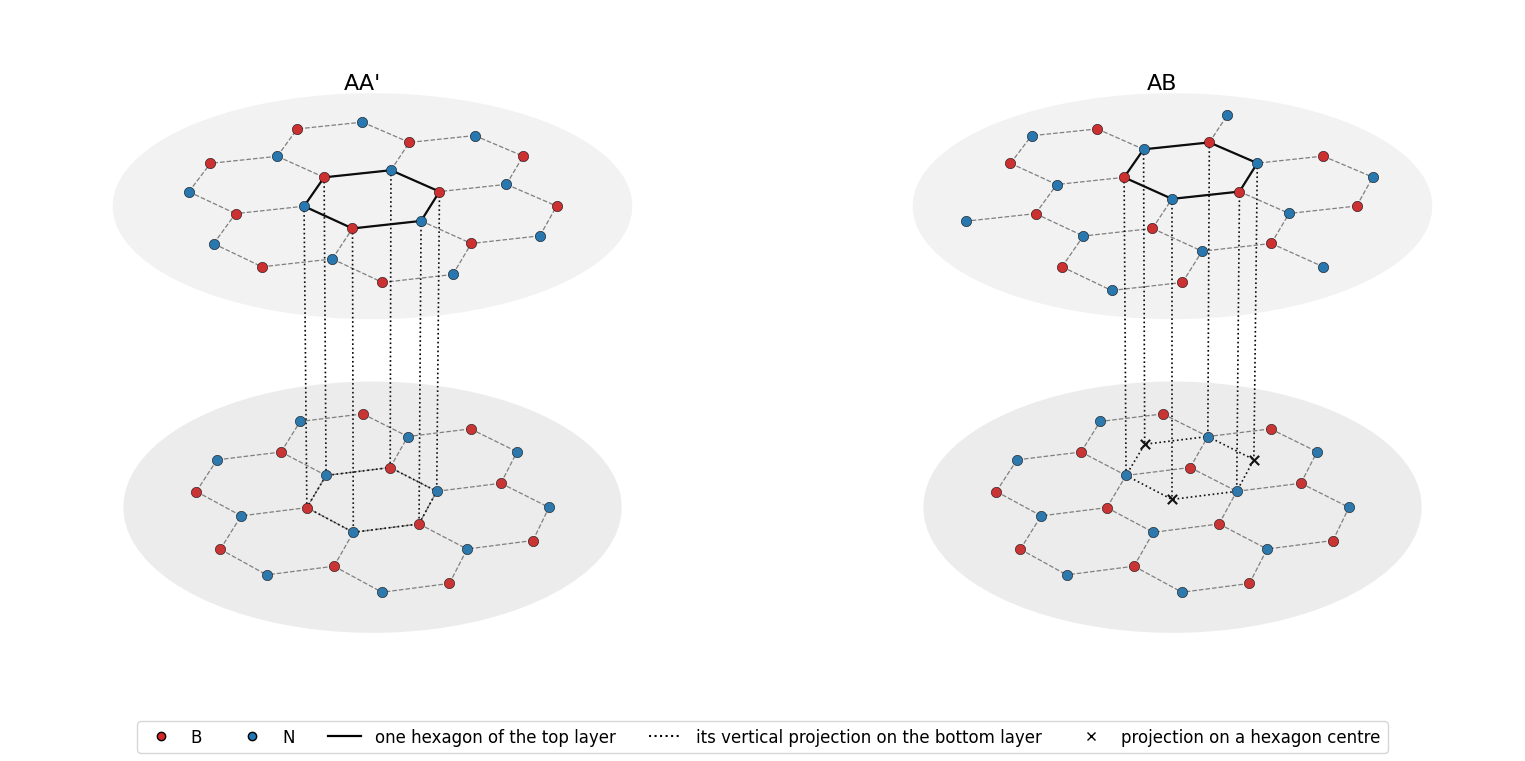

In [3]:
# Perspective view of the two layers: each layer is a plane of atoms with its hexagons (dashed); one hexagon of the
# top layer (solid) is projected vertically on the bottom layer (dotted lines): on an atom (circle) or on a hexagon
# centre (cross).
from mpl_toolkits.mplot3d.art3d import Poly3DCollection

a1, a2 = np.array(gs['lattice_vectors'][0][:2]), np.array(gs['lattice_vectors'][1][:2])
bond = np.linalg.norm(a1) / np.sqrt(3)
col = {'B': 'tab:red', 'N': 'tab:blue'}
R = 4.8                                                  # radius of the drawn patch (angstrom)

def layers(system):
    # atoms grouped by layer, bottom -> top: [(z, [(species, xy), ...]), ...]
    out = {}
    for at in gs['systems'][system]['atoms']:
        out.setdefault(round(at['position'][2], 3), []).append((at['species'], np.array(at['position'][:2])))
    return sorted(out.items())

def patch(atoms):
    # atoms of the layer within R of the origin, and the hexagon centre closest to the origin
    pts = [(s, p + n1 * a1 + n2 * a2) for s, p in atoms for n1 in range(-4, 5) for n2 in range(-4, 5)]
    pts = [(s, p) for s, p in pts if np.linalg.norm(p) < R]
    c0 = 2 * atoms[0][1] - atoms[1][1]                   # third site of the honeycomb = hexagon centre
    centres = [c0 + n1 * a1 + n2 * a2 for n1 in range(-3, 4) for n2 in range(-3, 4)]
    return pts, min(centres, key=np.linalg.norm)

def draw_layer(ax, pts, z, alpha):
    ang = np.linspace(0, 2 * np.pi, 80)
    ax.add_collection3d(Poly3DCollection([[(1.12 * R * np.cos(t), 1.12 * R * np.sin(t), z) for t in ang]],
                                         color='gray', alpha=alpha, lw=0))
    for i, (_, p) in enumerate(pts):
        for _, q in pts[i + 1:]:
            if abs(np.linalg.norm(p - q) - bond) < 1e-3:
                ax.plot([p[0], q[0]], [p[1], q[1]], [z, z], color='gray', ls='--', lw=0.9)
    for s, p in pts:
        ax.scatter(p[0], p[1], z, color=col[s], s=55, depthshade=False, edgecolors='k', linewidths=0.4)

fig = plt.figure(figsize=(16, 7.5))
for i, s in enumerate(['AA1', 'AB']):
    ax = fig.add_subplot(1, 2, i + 1, projection='3d')
    (zb, bot), (zt, top) = layers(s)
    pb, _ = patch(bot); pt, ct = patch(top)
    draw_layer(ax, pb, zb, 0.15); draw_layer(ax, pt, zt, 0.10)
    hexagon = [p for _, p in pt if abs(np.linalg.norm(p - ct) - bond) < 1e-3]
    hexagon.sort(key=lambda p: np.arctan2(*(p - ct)[::-1]))
    hx = hexagon + hexagon[:1]
    ax.plot([p[0] for p in hx], [p[1] for p in hx], [zt] * len(hx), color='k', lw=1.6)
    ax.plot([p[0] for p in hx], [p[1] for p in hx], [zb] * len(hx), color='k', ls=':', lw=1.2)
    for p in hexagon:
        ax.plot([p[0]] * 2, [p[1]] * 2, [zt, zb], color='k', ls=':', lw=1.2)
        if not any(np.allclose(p, q, atol=1e-3) for _, q in pb):
            ax.scatter(p[0], p[1], zb, marker='x', color='k', s=45, depthshade=False)
    ax.set_title('%s' % labels[s], size=16, y=0.95)
    # view azimuth chosen so that no vertical line crosses other atoms
    ax.view_init(elev=28, azim=-74); ax.set_box_aspect((1, 1, 0.75)); ax.set_axis_off()
    ax.set_xlim(-R, R); ax.set_ylim(-R, R); ax.set_zlim(zb, zt)
h = [plt.Line2D([], [], marker='o', ls='', color=col[x], markeredgecolor='k', label=x) for x in col]
h += [plt.Line2D([], [], color='k', lw=1.6, label='one hexagon of the top layer'),
      plt.Line2D([], [], color='k', ls=':', label='its vertical projection on the bottom layer'),
      plt.Line2D([], [], marker='x', ls='', color='k', label='projection on a hexagon centre')]
fig.legend(handles=h, loc='lower center', ncol=5, fontsize=12)
plt.subplots_adjust(left=0, right=1, top=1, bottom=0.06, wspace=0)

## DFT (PBE) ground state
Total energies and gaps on the k grid of the scf (12x12x1, which contains $\Gamma$, M and K).

In [4]:
print('%-11s %16s %12s %16s %14s' % ('system', 'E_tot (Ha)', 'gap (eV)', 'direct gap (eV)', 'gap at G (eV)'))
for s, v in gs['systems'].items():
    print('%-11s %16.6f %12.4f %16.4f %14.4f' % (s, v['total_energy_Ha'], v['gap'], v['direct_gap'], v['gap_Gamma']))

system            E_tot (Ha)     gap (eV)  direct gap (eV)  gap at G (eV)
ML_bot            -12.880929       4.7146           4.7146         6.0871
ML_top_AA1        -12.880929       4.7145           4.7145         6.0871
ML_top_AB         -12.880929       4.7144           4.7144         6.0870
AA1               -25.761078       4.5412           4.7649         6.1911
AB                -25.761102       4.5355           4.5851         6.1464


- The three monolayers coincide (within 0.2 meV): same crystal, moved or rotated in the cell.
- Monolayer: direct gap at K, 4.715 eV; the lowest conduction state at $\Gamma$ (nearly-free-electron, NFE, state)
  is almost degenerate with the one at K (within 1 meV).
- Bilayers: indirect gap K $\to$ M, 0.17-0.18 eV below the monolayer gap. The two stackings are degenerate in PBE
  (AB lower by 0.65 meV per cell).

## DFT (PBE) band structures

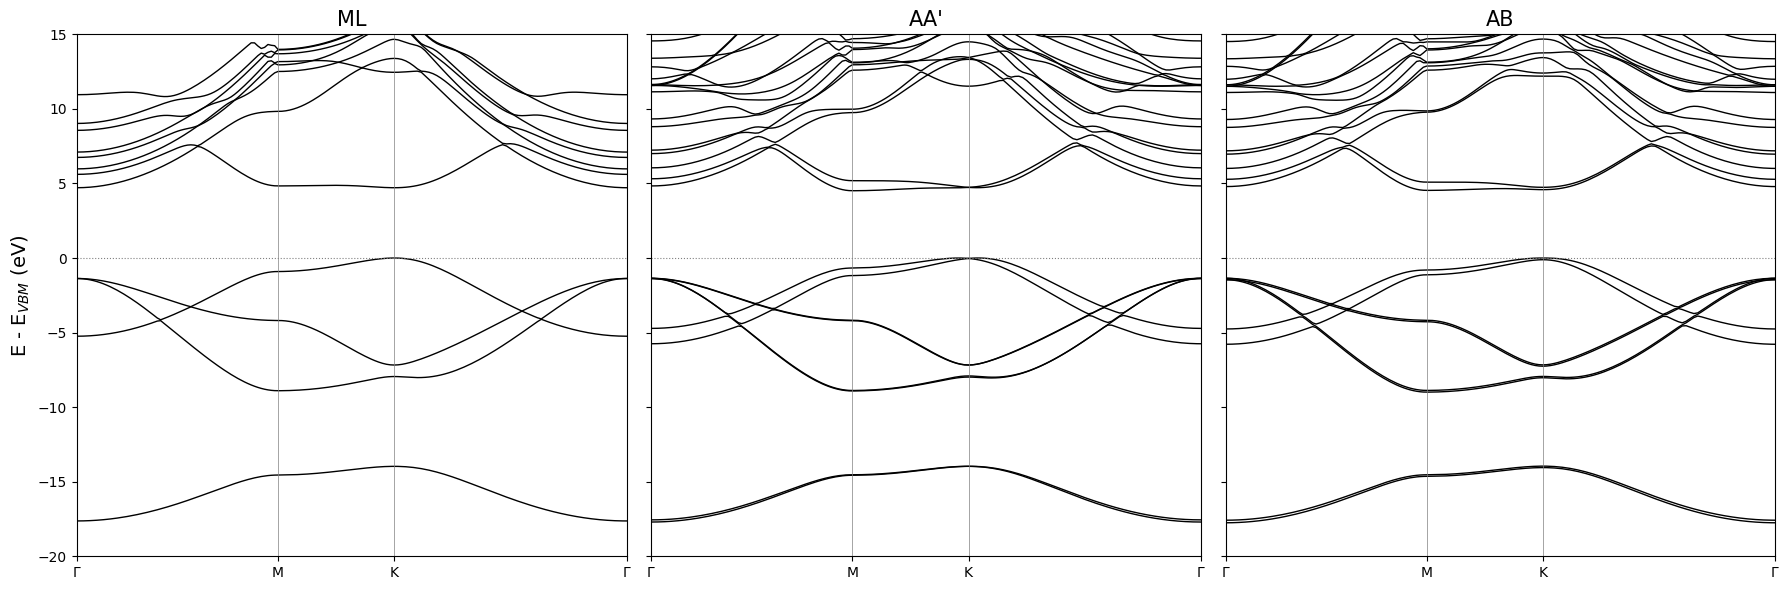

In [5]:
def plot_bands(ax, d, system, **kw):
    v = d['systems'][system]
    k, E = np.array(v['kpath']), np.array(v['bands'])
    for i, e in enumerate(E): ax.plot(k, e, label=kw.pop('label', None) if i == 0 else None, **kw)
    pos = v['high_symmetry_positions']
    for x in pos: ax.axvline(x, color='gray', lw=0.5)
    ax.set_xticks(pos); ax.set_xticklabels([tex_k[l] for l in d['path']['labels']]); ax.set_xlim(pos[0], pos[-1])

fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 6), sharey=True)
for a, s in zip(ax, ['ML_bot', 'AA1', 'AB']):
    plot_bands(a, dft_bands, s, color='k', lw=1)
    a.axhline(0, color='gray', ls=':', lw=0.8); a.set_title(labels[s], size=15)
ax[0].set_ylabel('E - E$_{VBM}$ (eV)', size=14); ax[0].set_ylim(-20, 15)
plt.tight_layout()

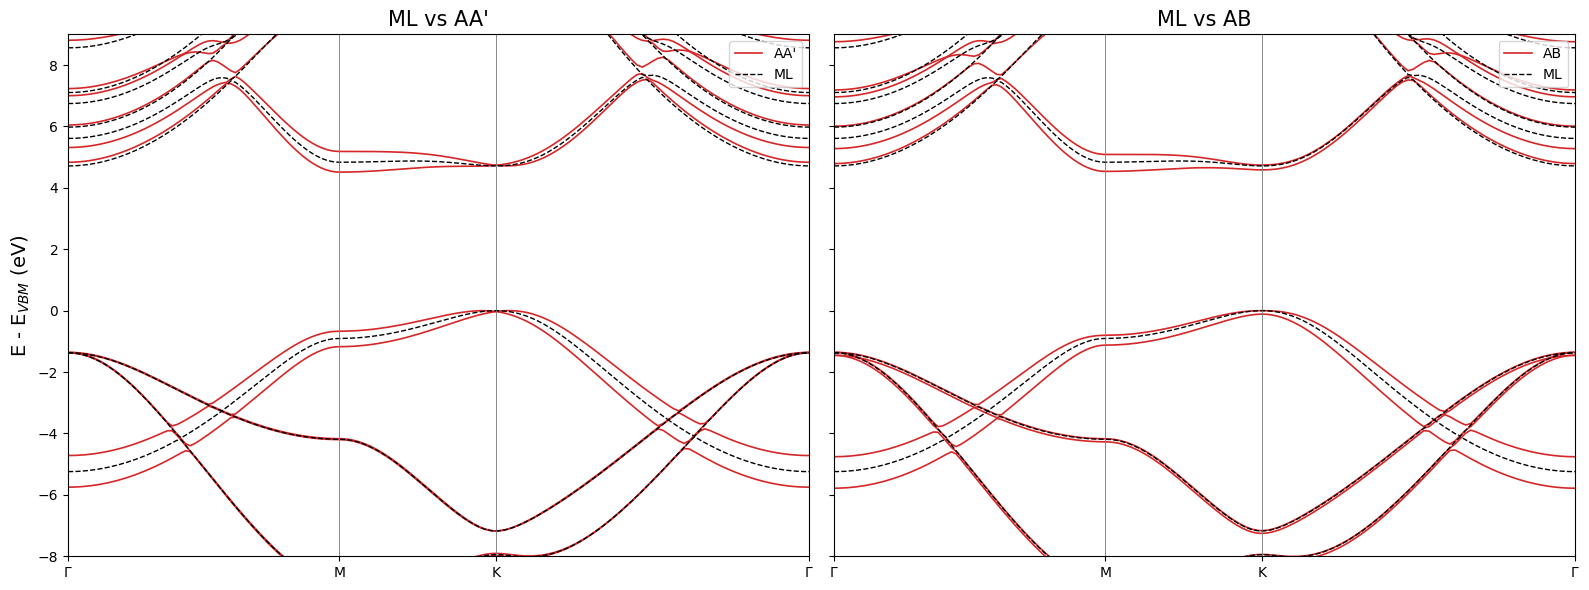

In [6]:
# Monolayer vs bilayers, window around the gap (each system from its own VBM)
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6), sharey=True)
for a, s in zip(ax, ['AA1', 'AB']):
    plot_bands(a, dft_bands, s, color='tab:red', lw=1.2, label=labels[s])
    plot_bands(a, dft_bands, 'ML_bot', color='k', lw=1, ls='--', label='ML')
    a.set_ylim(-8, 9); a.set_title('ML vs %s' % labels[s], size=15); a.legend(loc='upper right')
ax[0].set_ylabel('E - E$_{VBM}$ (eV)', size=14)
plt.tight_layout()

In [7]:
# Band edges at the high-symmetry points (eV, from the VBM on the path)
def at_point(system, label):
    v = dft_bands['systems'][system]
    ik = int(np.argmin(abs(np.array(v['kpath']) - v['high_symmetry_positions'][dft_bands['path']['labels'].index(label)])))
    E, nv = np.array(v['bands'])[:, ik], v['n_occupied_bands']
    nl = nv // 4                                   # number of layers: top valence / lowest conduction pair
    return E[nv - nl:nv], E[nv:nv + nl]
print('%-8s %-6s %-22s %-22s' % ('system', 'k', 'top valence', 'lowest conduction'))
for s in ['ML_bot', 'AA1', 'AB']:
    for l in ['Gamma', 'M', 'K']:
        v, c = at_point(s, l)
        print('%-8s %-6s %-22s %-22s' % (labels[s], l, ', '.join('%.3f' % x for x in v), ', '.join('%.3f' % x for x in c)))
for s in ['AA1', 'AB']:
    v = dft_bands['systems'][s]; E = np.array(v['bands']); nv = v['n_occupied_bands']
    iv, ic = E[nv - 1].argmax(), E[nv].argmin()
    print('%s: VBM at path coordinate %.4f (K at %.4f), CBM at %.4f (M at %.4f); gap on the path %.4f eV'
          % (labels[s], v['kpath'][iv], v['high_symmetry_positions'][2], v['kpath'][ic], v['high_symmetry_positions'][1],
             E[nv].min() - E[nv - 1].max()))

system   k      top valence            lowest conduction     
ML       Gamma  -1.372                 4.714                 
ML       M      -0.905                 4.834                 
ML       K      0.000                  4.714                 
AA'      Gamma  -1.358, -1.358         4.833, 5.314          
AA'      M      -1.173, -0.670         4.513, 5.185          
AA'      K      -0.029, -0.029         4.736, 4.736          
AB       Gamma  -1.355, -1.355         4.791, 5.278          
AB       M      -1.123, -0.803         4.535, 5.088          
AB       K      -0.113, 0.000          4.585, 4.741          
AA': VBM at path coordinate 0.9440 (K at 0.9107), CBM at 0.5774 (M at 0.5774); gap on the path 4.5125 eV
AB: VBM at path coordinate 0.9107 (K at 0.9107), CBM at 0.5774 (M at 0.5774); gap on the path 4.5352 eV


- **At K** the AA' states stay pairwise degenerate (equivalent layers, weak coupling of the K states): the direct gap
  at K changes by only +22 meV with respect to the monolayer. In AB the two layers are inequivalent and the K states
  split by 0.11 eV (valence) and 0.16 eV (conduction).
- **At M and $\Gamma$** the $\pi$/$\pi^*$ states and the NFE states of the two layers hybridize strongly
  (bonding/antibonding splittings of 0.5-0.67 eV): the bilayer CBM moves to M and the gap becomes indirect,
  K $\to$ M, 0.17 eV below the monolayer gap. This is a ground-state hybridization effect, not a screening effect.
- In AA' the VBM is slightly off K, towards $\Gamma$ (29 meV above the value at K): the gaps on the path are
  smaller than those on the k grids, which contain K but not this point.
- Consequence for the benchmark: the assumption of no overlap between the states of the two layers (Notes, Sec. 2.1)
  holds at K and fails for the conduction states at M and $\Gamma$. The effective scheme keeps the KS states of the
  free-standing layer, so it cannot reproduce the DFT differences above: the explicit vs effective comparison is
  made on the quasiparticle corrections (QP - KS) at K.

### Layer character of the bilayer states at $\Gamma$ and K
Fraction of $|\psi_{nk}|^2$ in the bottom layer (bands 7-8 valence, 9-10 conduction).

In [8]:
print('%-6s %-6s ' % ('system', 'k') + ''.join('%8s' % ('b' + b) for b in ['7', '8', '9', '10']))
for s, v in lay['systems'].items():
    for k, w in v.items():
        print('%-6s %-6s ' % (labels[s], k) + ''.join('%8.3f' % w[b] for b in ['7', '8', '9', '10']))

system k            b7      b8      b9     b10
AA'    Gamma     0.500   0.500   0.499   0.500
AA'    K         0.499   0.500   0.499   0.500
AB     Gamma     0.003   0.003   0.565   0.437
AB     K         0.989   0.006   0.977   0.021


- AA': degenerate pairs, 50/50 on the two layers (equivalent layers); any combination of a pair, also the
  layer-localized one, has the same GW correction.
- AB at K: states localized on one layer (98-99%): b7 (valence) and b9 (conduction) on the bottom layer, b8 and b10
  on the top layer. The KS gap b9 - b8 at K is an **interlayer** gap; the gaps of the single layers at K are
  b9 - b7 (bottom) and b10 - b8 (top). At $\Gamma$ the top valence pair is on the top layer, the NFE conduction
  states are spread over both layers.

## GW (G0W0, PPA) quasiparticle band structures
G0W0 with the plasmon-pole approximation at the converged parameters (GW_Analysis.ipynb; k = 18x18x1, NGsBlkXp = 6 Ha,
BndsRnXp = GbndRnge = 200 for ML and 212 for the bilayers, i.e. the same energy window, Bruneval-Gonze terminator,
slab cutoff with RIM and RIM_W). QP corrections computed on the whole IBZ (37 k points) for the bands 2-8 (ML) and
3-14 (bilayers), interpolated by ypp on the path and added to the exact KS bands of the pw.x bands run. The QP
energies are labelled by yambo with the KS band index; the plots order them in energy at each k (where the
corrections of crossing states differ, e.g. $\pi^*$ and NFE, the QP order differs from the KS one). DFT vs GW
panels: 3 valence bands and the lowest conduction band per layer (ML 2-5, bilayers 3-10); ML vs bilayer
panels: 3 valence and 3 conduction bands per layer (ML 2-7, bilayers 3-14).

Accuracy of the interpolation: exact at the grid points (dots: yambo values at the 17 points of the grid on the path,
within 4 meV of the curves); smooth for the valence bands. For the conduction bands the correction jumps between
$\pi^*$ states (about +1.1-1.3 eV) and nearly-free-electron states (about +0.5-0.6 eV) where the bands cross, and
between grid points near the crossings the curves can be off by 0.2-0.3 eV. Each band structure is plotted from its
own VBM on the path.

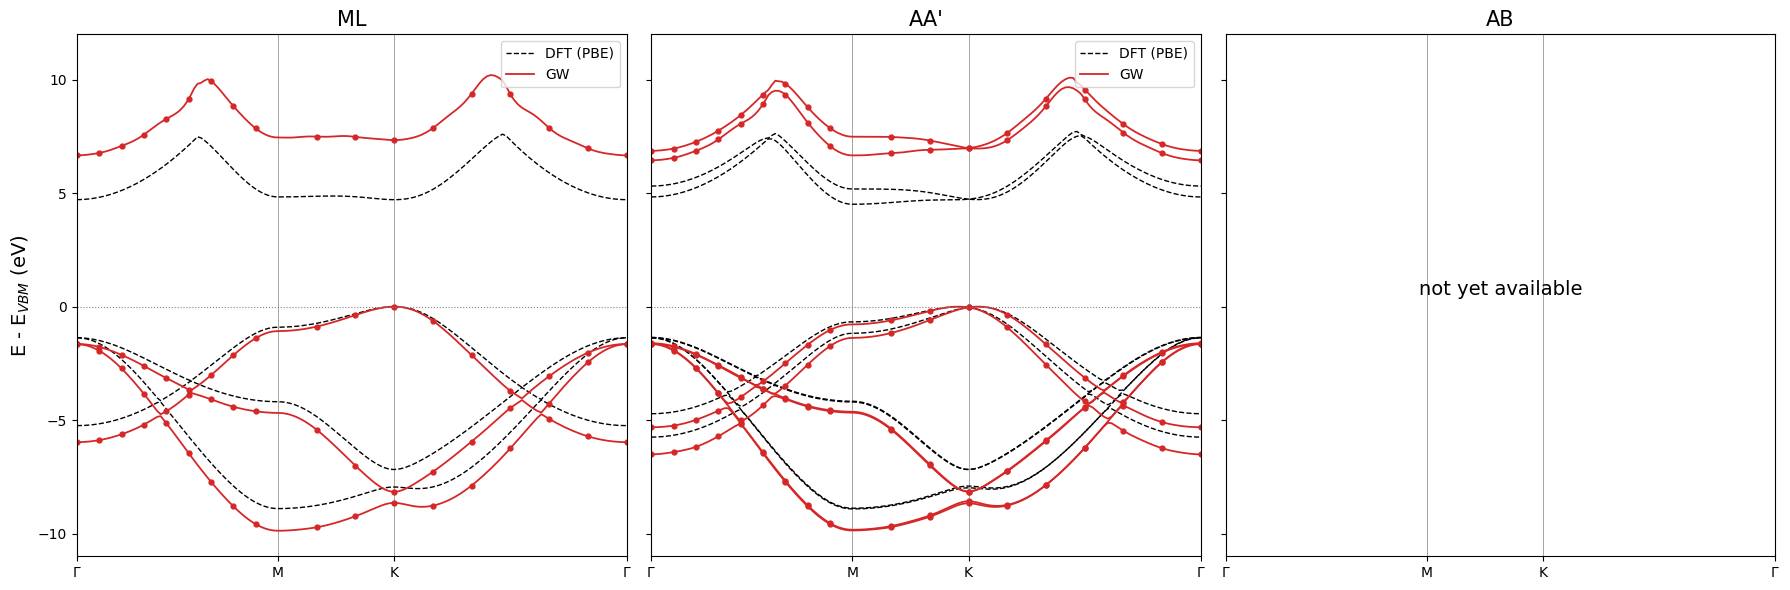

In [9]:
# bands shown in the plots: 3 valence + 3 conduction bands per layer (user, 2026-11-13); the files hold more
plot_range = {'ML_bot': (2, 7), 'AA1': (3, 14), 'AB': (3, 14)}

def bands_from_vbm(system, level):
    # energies (bands x k) of the GW file from the VBM on the path of the given level ('ks' or 'qp'), ordered in
    # energy at each k: the QP energies of the files are labelled by the KS band index, and where the corrections
    # differ (pi* +1.2 eV, NFE +0.6 eV) the QP order changes (e.g. the KS band 5 is not the lowest QP state)
    v = gw_bands['systems'][system]
    E = np.sort(np.array(v['bands_' + level]), axis=0); iv = v['top_valence_band'] - v['bands'][0]
    return E - E[iv].max(), E[iv].max()

# DFT vs GW panels: only the lowest conduction band of each layer (user, 2026-11-13)
plot_range_dft_gw = {'ML_bot': (2, 5), 'AA1': (3, 10), 'AB': (3, 10)}

def shown(system, E, brange=None):
    # rows of E (bands of the file) inside brange (default plot_range)
    b0 = gw_bands['systems'][system]['bands'][0]; p0, p1 = (brange or plot_range)[system]
    return E[p0 - b0:p1 - b0 + 1]

def plot_gw(ax, system, level, brange=None, **kw):
    v = gw_bands['systems'][system]; E, _ = bands_from_vbm(system, level)
    lab = kw.pop('label', None)
    for i, e in enumerate(shown(system, E, brange)): ax.plot(v['kpath'], e, label=lab if i == 0 else None, **kw)

def set_path_axis(ax):
    pos = gw_bands['path']['high_symmetry_positions']
    for x in pos: ax.axvline(x, color='gray', lw=0.5)
    ax.set_xticks(pos); ax.set_xticklabels([tex_k[l] for l in gw_bands['path']['labels']]); ax.set_xlim(pos[0], pos[-1])

gw_systems = [s for s in ['ML_bot', 'AA1', 'AB'] if s in gw_bands['systems']]
fig, ax = plt.subplots(nrows=1, ncols=3, figsize=(18, 6), sharey=True)
for a, s in zip(ax, ['ML_bot', 'AA1', 'AB']):
    a.set_title(labels[s], size=15); set_path_axis(a)
    if s not in gw_bands['systems']:
        a.text(0.5, 0.5, 'not yet available', transform=a.transAxes, ha='center', size=14); continue
    plot_gw(a, s, 'ks', brange=plot_range_dft_gw, color='k', lw=1, ls='--', label='DFT (PBE)')
    plot_gw(a, s, 'qp', brange=plot_range_dft_gw, color='tab:red', lw=1.3, label='GW')
    g = gw_bands['systems'][s]['grid_points_on_path']; _, vbm_qp = bands_from_vbm(s, 'qp')
    for e in shown(s, np.sort(np.array(g['E_qp']), axis=0), plot_range_dft_gw): a.plot(g['kpath'], e - vbm_qp, 'o', color='tab:red', ms=3.5)
    a.axhline(0, color='gray', ls=':', lw=0.8); a.legend(loc='upper right')
ax[0].set_ylabel('E - E$_{VBM}$ (eV)', size=14); ax[0].set_ylim(-11, 12)
plt.tight_layout()

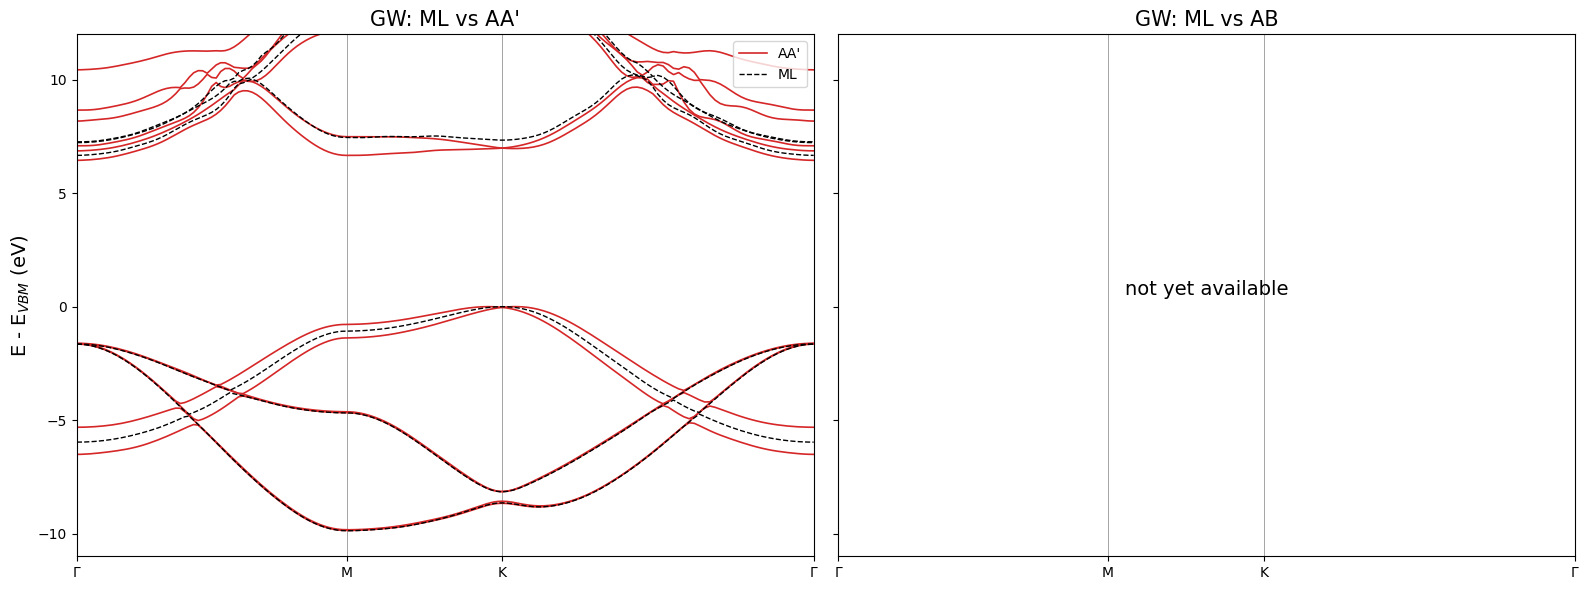

In [10]:
# GW: monolayer vs bilayers (each from its own VBM)
fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(16, 6), sharey=True)
for a, s in zip(ax, ['AA1', 'AB']):
    a.set_title('GW: ML vs %s' % labels[s], size=15); set_path_axis(a)
    if s not in gw_bands['systems']:
        a.text(0.5, 0.5, 'not yet available', transform=a.transAxes, ha='center', size=14); continue
    plot_gw(a, s, 'qp', color='tab:red', lw=1.2, label=labels[s])
    plot_gw(a, 'ML_bot', 'qp', color='k', lw=1, ls='--', label='ML')
    a.set_ylim(-11, 12); a.legend(loc='upper right')
ax[0].set_ylabel('E - E$_{VBM}$ (eV)', size=14)
plt.tight_layout()

In [11]:
# Gaps on the path (eV): direct at K and at Gamma, fundamental gap with the positions of VBM and CBM
pos = gw_bands['path']['high_symmetry_positions']; names = gw_bands['path']['labels']
def where(x):
    for p, l in zip(pos, names):
        if abs(x - p) < 1e-4: return l
    j = int(np.searchsorted(pos, x)); return 'near %s' % (names[j - 1] if x - pos[j - 1] < pos[j] - x else names[j])
print('%-5s %-4s %8s %8s %10s   %s' % ('', '', 'K-K', 'G-G', 'gap', 'VBM -> CBM'))
for s in gw_systems:
    v = gw_bands['systems'][s]; k = np.array(v['kpath']); iv = v['top_valence_band'] - v['bands'][0]
    iK, iG = int(np.argmin(abs(k - pos[2]))), 0
    for level in ['ks', 'qp']:
        E, _ = bands_from_vbm(s, level)
        jv, jc = E[iv].argmax(), E[iv + 1].argmin()
        print('%-5s %-4s %8.3f %8.3f %10.3f   %s -> %s' % (labels[s], 'DFT' if level == 'ks' else 'GW', E[iv + 1, iK] - E[iv, iK],
              E[iv + 1, iG] - E[iv, iG], E[iv + 1].min(), where(k[jv]), where(k[jc])))

                K-K      G-G        gap   VBM -> CBM
ML    DFT     4.714    6.087      4.714   K -> K
ML    GW      7.338    8.312      6.666   K -> Gamma
AA'   DFT     4.765    6.191      4.513   near K -> M
AA'   GW      7.018    8.062      6.449   near K -> Gamma


Results (ML and AA'; AB when its full-IBZ run is complete):
- **ML**: GW gap at K 7.338 eV (DFT 4.714), at $\Gamma$ 8.312 eV; the fundamental GW gap is indirect, K $\to$ $\Gamma$,
  6.666 eV: the nearly-free-electron state at $\Gamma$ gets a much smaller correction than the $\pi^*$ state at K.
- **AA'**: GW gap at K 7.018 eV (DFT 4.765), at $\Gamma$ 8.062 eV; fundamental GW gap 6.449 eV, from the VBM near K
  (off K, as in DFT) to $\Gamma$. In DFT the CBM is at M (hybridized $\pi^*$ state): GW moves it to $\Gamma$, for the
  same reason as in the monolayer.
- ML vs AA' at the GW level: the bilayer gaps at K are 0.32 eV smaller (-0.37 eV from the GW correction, +0.05 eV
  from DFT, GW_Analysis.ipynb): the extra screening of the second layer reduces the QP corrections. This GW
  correction is what the effective scheme has to reproduce.